<a href="https://colab.research.google.com/github/MSGamgee85/Projetos/blob/main/Equacao_Transporte.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![Google Colab](https://img.shields.io/badge/Google%20Colab-%23F9A825.svg?style=for-the-badge&logo=googlecolab&logoColor=black) ![NumPy](https://img.shields.io/badge/numpy-%23013243.svg?style=for-the-badge&logo=numpy&logoColor=white) ![Pandas](https://img.shields.io/badge/pandas-%23150458.svg?style=for-the-badge&logo=pandas&logoColor=white)

---

## **Equação Diferencial Parcial de Transporte** 🚢

---



A **equação de transporte** é uma equação diferencial parcial (EDP) linear de primeira ordem que descreve o <u>movimento e o espalhamento</u> de uma grandeza física (calor, massa, densidade, fluido, etc.) em um dado meio.

<br>

$\boxed{\sf \dfrac{\partial \phi}{\partial t}+c\dfrac{\partial \phi}{\partial x}= 0}$

<br>

onde:

* $\sf \phi = \phi(t, x)$ = **fluxo** (matéria, informação, etc.);

* $\sf c$ =  **número de Courant** (de forma simplificada, representa o *fluxo de informação/velocidade* em um meio). Valores diferentes desse número permitem classificar a solução da EDP em <u> estática,</u> <u> estável </u> ou <u> instável. </u>

<br>

---

 Em **finanças**, essa estrutura matemática é adaptada para modelar a <u> evolução temporal de preços e incertezas (volatilidade) de ativos </u> no mercado de capitais. 📈

---

 <br>

 Neste notebook vamos resolver a EDP de Transporte utilizando o **Método das Diferenças Finitas (MDF)**, que consiste em utilizar <u>aproximações numéricas</u> para as derivadas da expressão original. Assim, é possível obter uma *relação de recorrência* que permite calcular os pontos da curva (**solução gráfica**) da EDP. Vamos obter as soluções para diversos valores do número de Courant a fim de analisar o comportamento da solução.

<br>

## **Referências**

---

SALES, R. M. **Método das diferenças finitas - Notas de aula**. MBA em Engenharia Financeira. Poli, USP. São Paulo, 2026.

WIKIPEDIA. **Método das diferenças finitas**. Disponível em: < https://pt.wikipedia.org/wiki/M%C3%A9todo_das_diferen%C3%A7as_finitas > . Acesso em: 06 mai. 2026

## **Configuração do ambiente**
---

In [ ]:
# -- Bibliotecas utilizadas --
import numpy as np                  # funções matemáticas e operações com vetores e matrizes
import pandas as pd                 # estruturas tabulares de organização e análise de dados
import matplotlib.pyplot as plt     # geração de gráficos e visualizações
import warnings                     # gestão de alertas da IDE
warnings.filterwarnings('ignore')   # ignora os alertas ao rodar o código

In [ ]:
# -- Parâmetros do problema --

# Limites grade discretização [0, T] x [0, X]
T = 0.5
X = 0.5

# Passo de discretização (fixo) - necessário para o MDF
dt = 0.1
dx = 0.1



## **a. Solução para c = 1.0**
---

In [ ]:
# -- Geração da tabela de dados -- #

# Parâmetros do problema
c = 1.0
C = c * dt / dx # número de Courant

# Inicia a matriz de resultados
x = np.arange(0, 0.6, dx) # contagem em Python termina em n-1
t = np.arange(0, 0.6, dt)

# Calcula valores de phi na matriz (linhas = tempo, colunas = espaço)
phi = np.ones((len(t), len(x))) # phi tem valor constante = 1.0

# Geramos a tabela de dados
df_a = pd.DataFrame(phi, index=[f't={round(i,1)}' for i in t],
                    columns=[f'x={round(j,1)}' for j in x])

print("Tabela Solução da EDP de Transporte (c = 1.0)")
print("-"*48)
display(df_a)

Tabela Solução da EDP de Transporte (c = 1.0)
------------------------------------------------


,x=0.0,x=0.1,x=0.2,x=0.3,x=0.4,x=0.5
t=0.0,1.0,1.0,1.0,1.0,1.0,1.0
t=0.1,1.0,1.0,1.0,1.0,1.0,1.0
t=0.2,1.0,1.0,1.0,1.0,1.0,1.0
t=0.3,1.0,1.0,1.0,1.0,1.0,1.0
t=0.4,1.0,1.0,1.0,1.0,1.0,1.0
t=0.5,1.0,1.0,1.0,1.0,1.0,1.0


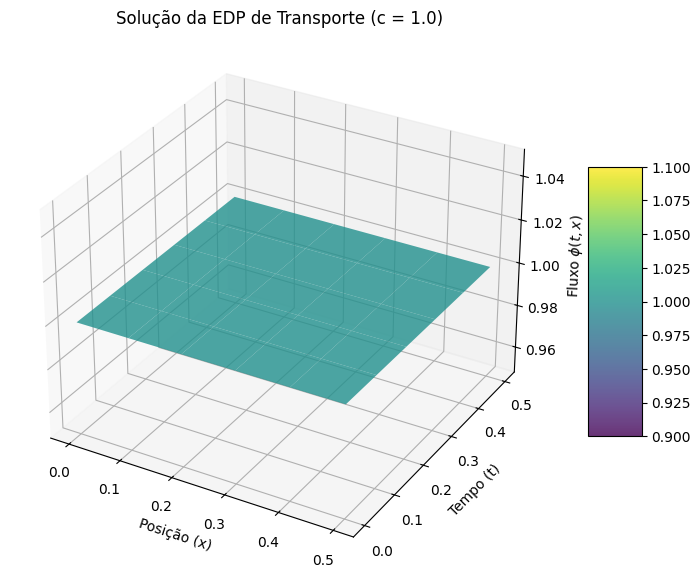

In [ ]:
# -- Geração do gráfico da solução --#

# Parâmetros
X = 0.5
T = 0.5

# Criação da malha (grid)
x = np.arange(0, X + dx, dx)
t = np.arange(0, T + dt, dt)
X, T = np.meshgrid(x, t)

# Inicia matriz de resultados (linhas = tempo, colunas = espaço)
phi = np.zeros((len(t), len(x)))

# Condição Inicial:
phi[0, :] = 1.0

# Aplicamos a aproximação simétrica para gerar os pontos
for j in range(0, len(t) - 1):
    for i in range(1, len(x)):
        phi[j+1, i] = phi[j, i] - C * (phi[j, i] - phi[j, i-1])

    # Forçamos as condições de contorno
    phi[j+1, -1] = 1.0
    phi[j+1, 0] = 1.0

# Plotagem 3D
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(X, T, phi, cmap='viridis', edgecolor='none', alpha = 0.8)

ax.set_xlabel('Posição (x)')
ax.set_ylabel('Tempo (t)')
ax.set_zlabel('Fluxo $\phi(t, x)$')
ax.set_title('Solução da EDP de Transporte (c = 1.0)')

plt.colorbar(surf, ax=ax, shrink=0.5, aspect=5)
plt.show()

---

**Comentário**: a solução é **estática**, representada por uma superfície de altura constante.

---


## **b. Solução para c = 0.1**
---

In [ ]:
# -- Geração da tabela de dados -- #

# Parâmetros do problema
c = 0.1
C = c * dt / dx

# Inicia matriz de resultados (linhas = tempo, colunas = espaço)
x = np.round(np.arange(0, 0.6, dx), 1)
t = np.round(np.arange(0, 0.6, dt), 1)
phi = np.zeros((len(t), len(x)))

# Condição inicial:
phi[0, :] = x

# Aplicamos a aproximação simétrica para gerar os pontos
for j in range(0, len(t) - 1):
    for i in range(1, len(x)):
        phi[j+1, i] = phi[j, i] - C * (phi[j, i] - phi[j, i-1])

    # Forçamos a condição de contorno coerente com o gráfico consolidado em x=0.5 para t > 0
    phi[j+1, -1] = 1.0

# Geramos a tabela de dados
df_b = pd.DataFrame(phi, index=[f't={i}' for i in t],
                    columns=[f'x={j}' for j in x])

print("Tabela Solução da EDP de Transporte (c = 0.1)")
print("-"*54)
display(df_b.round(4))

Tabela Solução da EDP de Transporte (c = 0.1)
------------------------------------------------------


,x=0.0,x=0.1,x=0.2,x=0.3,x=0.4,x=0.5
t=0.0,0.0,0.1000,0.2000,0.30,0.40,0.5
t=0.1,0.0,0.0900,0.1900,0.29,0.39,1.0
t=0.2,0.0,0.0810,0.1800,0.28,0.38,1.0
t=0.3,0.0,0.0729,0.1701,0.27,0.37,1.0
t=0.4,0.0,0.0656,0.1604,0.26,0.36,1.0
t=0.5,0.0,0.0590,0.1509,0.25,0.35,1.0


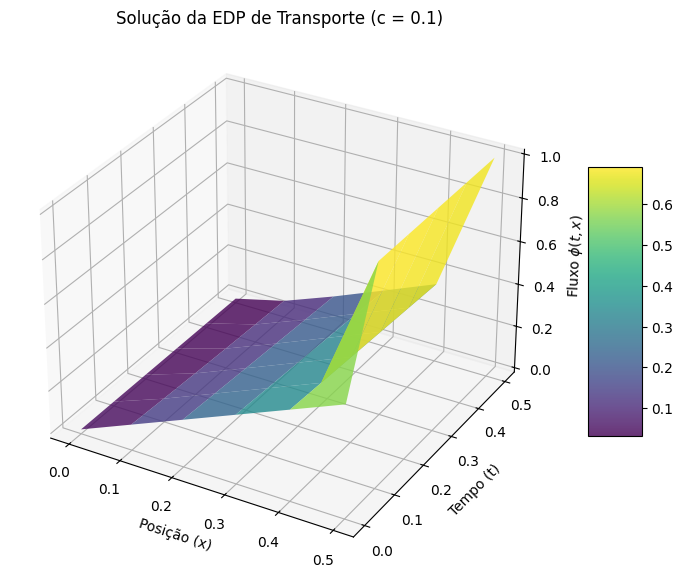

In [ ]:
# -- Geração do gráfico da solução -- #

# Parâmetros do problema
X = 0.5
T = 0.5

# Criação da malha (grid)
x = np.arange(0, X + dx, dx)
t = np.arange(0, T + dt, dt)
X, T = np.meshgrid(x, t)

# Inicia matriz de resultados (linhas = tempo, colunas = espaço)
phi = np.zeros((len(t), len(x)))

# Condição Inicial:
phi[0, :] = x

# Aplicamos a aproximação simétrica para gerar os pontos
for j in range(0, len(t) - 1):
    for i in range(1, len(x)):
        phi[j+1, i] = phi[j, i] - C * (phi[j, i] - phi[j, i-1])

    # Forçamos a condição de contorno coerente com o gráfico consolidado em x=0.5 para t > 0
    phi[j+1, -1] = 1.0

# Plotagem 3D
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(X, T, phi, cmap='viridis', edgecolor='none', alpha=0.8)

ax.set_xlabel('Posição (x)')
ax.set_ylabel('Tempo (t)')
ax.set_zlabel('Fluxo $\phi(t, x)$')
ax.set_title('Solução da EDP de Transporte (c = 0.1)')

plt.colorbar(surf, ax=ax, shrink=0.5, aspect=5)
plt.show()

---

**Comentário**: temos uma solução **estável**, escoamento em nível acima.

---


## **c. Solução para c = 3.0**
---

In [ ]:
# -- Geração da tabela de dados -- #

# Parâmetros do problema
c = 3.0
C = c * dt / dx   # número de Courant

# Inicia matriz de resultados (linhas = tempo, colunas = espaço)
phi = np.zeros((len(t), len(x)))

# Condições iniciais
phi[0, :] = [(-1)**i for i in range(len(x))]

# Aplicamos a aproximação simétrica para gerar os pontos
for j in range(0, len(t) - 1):
    for i in range(1, len(x)):
        phi[j+1, i] = phi[j, i] - C * (phi[j, i] - phi[j, i-1])

    # Forçamos a condição de contorno coerente com o gráfico consolidado em x=0.5 para t > 0
    phi[j+1, -1] = 1.0

# Geramos a tabela de dados
df_c1 = pd.DataFrame(phi, index=[f't={round(i,1)}' for i in t],
                     columns=[f'x={round(j,1)}' for j in x])

print("Tabela Solução da EDP de Transporte (c = 3.0)")
print("-"*52)
display(df_c1)

Tabela Solução da EDP de Transporte (c = 3.0)
----------------------------------------------------


,x=0.0,x=0.1,x=0.2,x=0.3,x=0.4,x=0.5
t=0.0,1.0,-1.0,1.0,-1.0,1.0,-1.0
t=0.1,0.0,5.0,-5.0,5.0,-5.0,1.0
t=0.2,0.0,-10.0,25.0,-25.0,25.0,1.0
t=0.3,0.0,20.0,-80.0,125.0,-125.0,1.0
t=0.4,0.0,-40.0,220.0,-490.0,625.0,1.0
t=0.5,0.0,80.0,-560.0,1640.0,-2720.0,1.0


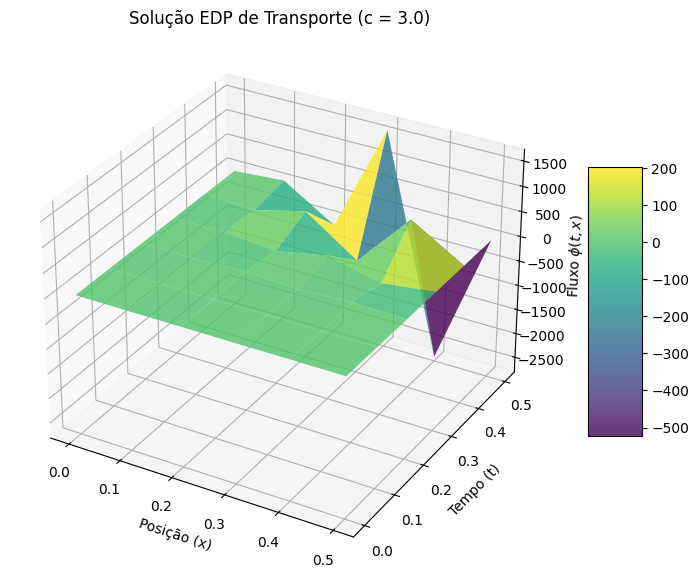

In [ ]:
# -- Geração do gráfico da solução -- #

# Parâmetros do problema
X = 0.5        # Limite de x
T = 0.5        # Limite de t

# Criação da malha (grid)
x = np.arange(0, X + dx, dx)
t = np.arange(0, T + dt, dt)
X, T = np.meshgrid(x, t)

# Inicia matriz de resultados (linhas = tempo, colunas = espaço)
phi = np.zeros((len(t), len(x)))

# Condição Inicial:
phi[0, :] = [(-1)**i for i in range(len(x))]

# Aplicamos a aproximação simétrica para gerar os pontos
for j in range(0, len(t) - 1):
    for i in range(1, len(x)):
        phi[j+1, i] = phi[j, i] - C * (phi[j, i] - phi[j, i-1])

    # Forçamos a condição de contorno coerente com o gráfico consolidado em x=0.5 para t > 0
    phi[j+1, -1] = 1.0

# Plotagem 3D
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(X, T, phi, cmap='viridis', edgecolor='none', alpha=0.8)

ax.set_xlabel('Posição (x)')
ax.set_ylabel('Tempo (t)')
ax.set_zlabel('Fluxo $\phi(t, x)$')
ax.set_title('Solução EDP de Transporte (c = 3.0)')

plt.colorbar(surf, ax=ax, shrink=0.5, aspect=5)
plt.show()

---

**Comentário**: solução **instável**, representada por picos e vales que aumentam indefinidamente <u> (explosão numérica)</u>.

---


## **d. Solução para c = 0.1 (diferente condição de contorno)**
---

In [ ]:
# -- Geração da tabela de dados -- #

# Parâmetros do problema
c = 0.1
C = c * dt / dx   # número de Courant

# Inicia matriz de resultados (linhas = tempo, colunas = espaço)
phi = np.zeros((len(t), len(x)))

# Condição inicial:
phi[0, :] = [(-1)**i for i in range(len(x))]

# Aplicamos a aproximação simétrica para gerar os pontos
for j in range(0, len(t) - 1):
    for i in range(1, len(x)):
        phi[j+1, i] = phi[j, i] - C * (phi[j, i] - phi[j, i-1])

    # Forçamos a condição de contorno coerente com o gráfico consolidado em x=0.5 para t > 0
    phi[j+1, -1] = 1.0

# Geramos a tabela de dados
df_c2 = pd.DataFrame(phi, index=[f't={round(i,1)}' for i in t],
                     columns=[f'x={round(j,1)}' for j in x])

print("Tabela Solução da EDP de Transporte (c = 0.1)")
print("-"*52)
display(df_c2.round(4))

Tabela Solução da EDP de Transporte (c = 0.1)
----------------------------------------------------


,x=0.0,x=0.1,x=0.2,x=0.3,x=0.4,x=0.5
t=0.0,1.0,-1.0000,1.0000,-1.0000,1.0000,-1.0
t=0.1,0.0,-0.8000,0.8000,-0.8000,0.8000,1.0
t=0.2,0.0,-0.7200,0.6400,-0.6400,0.6400,1.0
t=0.3,0.0,-0.6480,0.5040,-0.5120,0.5120,1.0
t=0.4,0.0,-0.5832,0.3888,-0.4104,0.4096,1.0
t=0.5,0.0,-0.5249,0.2916,-0.3305,0.3276,1.0


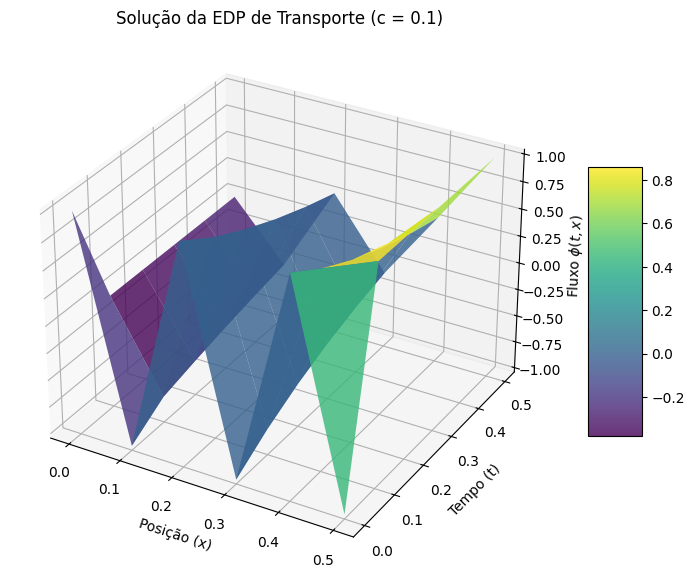

In [ ]:
# -- Geração do gráfico da solução -- #

# Parâmetros do problema
X = 0.5        # Limite de x
T = 0.5        # Limite de t

# Criação da malha (grid)
x = np.arange(0, X + dx, dx)
t = np.arange(0, T + dt, dt)
X, T = np.meshgrid(x, t)

# Inicia matriz de resultados (linhas = tempo, colunas = espaço)
phi = np.zeros((len(t), len(x)))

# Condição Inicial:
phi[0, :] = [(-1)**i for i in range(len(x))]

# Aplicamos a aproximação simétrica para gerar os pontos
for j in range(0, len(t) - 1):
    for i in range(1, len(x)):
        phi[j+1, i] = phi[j, i] - C * (phi[j, i] - phi[j, i-1])

    # Forçamos a condição de contorno coerente com o gráfico consolidado em x=0.5 para t > 0
    phi[j+1, -1] = 1.0

# Plotagem 3D
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(X, T, phi, cmap='viridis', edgecolor='none', alpha=0.8)

ax.set_xlabel('Posição (x)')
ax.set_ylabel('Tempo (t)')
ax.set_zlabel('Fluxo $\phi(t, x)$')
ax.set_title('Solução da EDP de Transporte (c = 0.1)')

plt.colorbar(surf, ax=ax, shrink=0.5, aspect=5)
plt.show()

---

**Comentário**: solução **estável** (com *amortecimento*), picos e vales decrescem com o passar do tempo atingindo o equilíbrio.

---


## **Exploração visual dos Resultados**
---

### **1. Tabelas Solução Consolidadas**

---

In [ ]:
# -- Exibição de todas as tabelas de dados -- #

import pandas as pd # Importar pandas novamente para garantir, embora já esteja no kernel

print("Tabela Item a (c = 1.0) → Solução Constante")
print("-"*50)
display(df_a)

print("\nTabela Item b (c = 0.1) → Solução Estável")
print("-"*50)
display(df_b.round(4))

print("\nTabela Item c (c = 3.0) → Solução Instável")
print("-"*52)
display(df_c1)

print("\nTabela Item d (c = 0.1) → Solução Estável (com amortecimento)")
print("-"*52)
display(df_c2.round(4))

Tabela Item a (c = 1.0) → Solução Constante
--------------------------------------------------


,x=0.0,x=0.1,x=0.2,x=0.3,x=0.4,x=0.5
t=0.0,1.0,1.0,1.0,1.0,1.0,1.0
t=0.1,1.0,1.0,1.0,1.0,1.0,1.0
t=0.2,1.0,1.0,1.0,1.0,1.0,1.0
t=0.3,1.0,1.0,1.0,1.0,1.0,1.0
t=0.4,1.0,1.0,1.0,1.0,1.0,1.0
t=0.5,1.0,1.0,1.0,1.0,1.0,1.0



Tabela Item b (c = 0.1) → Solução Estável
--------------------------------------------------


,x=0.0,x=0.1,x=0.2,x=0.3,x=0.4,x=0.5
t=0.0,0.0,0.1000,0.2000,0.30,0.40,0.5
t=0.1,0.0,0.0900,0.1900,0.29,0.39,1.0
t=0.2,0.0,0.0810,0.1800,0.28,0.38,1.0
t=0.3,0.0,0.0729,0.1701,0.27,0.37,1.0
t=0.4,0.0,0.0656,0.1604,0.26,0.36,1.0
t=0.5,0.0,0.0590,0.1509,0.25,0.35,1.0



Tabela Item c (c = 3.0) → Solução Instável
----------------------------------------------------


,x=0.0,x=0.1,x=0.2,x=0.3,x=0.4,x=0.5
t=0.0,1.0,-1.0,1.0,-1.0,1.0,-1.0
t=0.1,0.0,5.0,-5.0,5.0,-5.0,1.0
t=0.2,0.0,-10.0,25.0,-25.0,25.0,1.0
t=0.3,0.0,20.0,-80.0,125.0,-125.0,1.0
t=0.4,0.0,-40.0,220.0,-490.0,625.0,1.0
t=0.5,0.0,80.0,-560.0,1640.0,-2720.0,1.0



Tabela Item d (c = 0.1) → Solução Estável (com amortecimento)
----------------------------------------------------


,x=0.0,x=0.1,x=0.2,x=0.3,x=0.4,x=0.5
t=0.0,1.0,-1.0000,1.0000,-1.0000,1.0000,-1.0
t=0.1,0.0,-0.8000,0.8000,-0.8000,0.8000,1.0
t=0.2,0.0,-0.7200,0.6400,-0.6400,0.6400,1.0
t=0.3,0.0,-0.6480,0.5040,-0.5120,0.5120,1.0
t=0.4,0.0,-0.5832,0.3888,-0.4104,0.4096,1.0
t=0.5,0.0,-0.5249,0.2916,-0.3305,0.3276,1.0


### **2. Gráficos Consolidados**
---

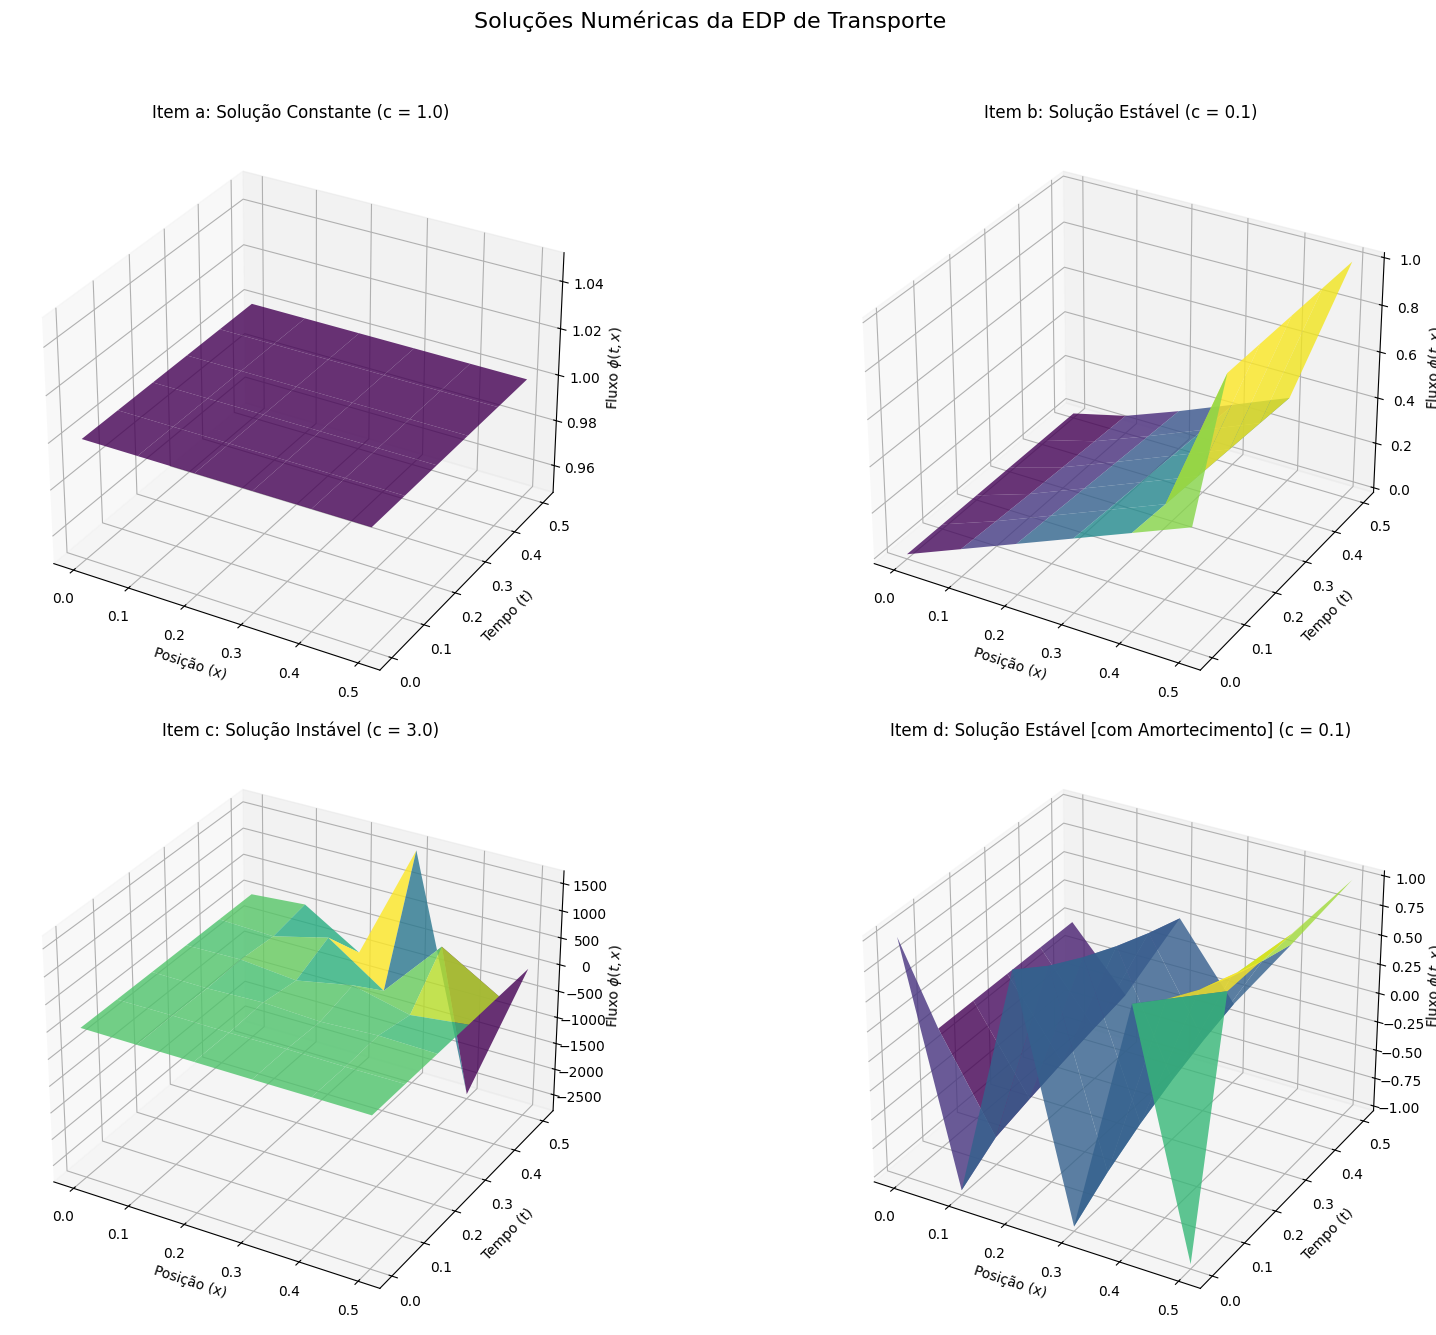

In [ ]:
# -- Geração de uma figura com todos os 4 gráficos -- #

# Parâmetros comuns
X = 0.5
T = 0.5

# Gera a grade de pontos
x = np.arange(0, X + dx, dx)
t = np.arange(0, T + dt, dt)
X_mesh, T_mesh = np.meshgrid(x, t)

fig = plt.figure(figsize=(18, 14))
fig.suptitle('Soluções Numéricas da EDP de Transporte', fontsize=16)

# --- Item a ---
ax1 = fig.add_subplot(2, 2, 1, projection='3d')

c_a = 1.0
C_a = c_a * dt / dx
phi_a = np.zeros((len(t), len(x)))
phi_a[0, :] = 1.0
for j in range(0, len(t) - 1):
    for i in range(1, len(x)):
        phi_a[j+1, i] = phi_a[j, i] - C_a * (phi_a[j, i] - phi_a[j, i-1])
    # Forçamos as condições de contorno
    phi_a[j+1, -1] = 1.0
    phi_a[j+1, 0] = 1.0

surf1 = ax1.plot_surface(X_mesh, T_mesh, phi_a, cmap='viridis', edgecolor='none', alpha=0.8)
ax1.set_title('Item a: Solução Constante (c = 1.0)')
ax1.set_xlabel('Posição (x)')
ax1.set_ylabel('Tempo (t)')
ax1.set_zlabel('Fluxo $\phi(t, x)$')
# fig.colorbar(surf1, ax=ax1, shrink=0.5, aspect=5)

# --- Item b ---
ax2 = fig.add_subplot(2, 2, 2, projection='3d')

c_b = 0.1
C_b = c_b * dt / dx
phi_b = np.zeros((len(t), len(x)))
phi_b[0, :] = x
for j in range(0, len(t) - 1):
    for i in range(1, len(x)):
        phi_b[j+1, i] = phi_b[j, i] - C_b * (phi_b[j, i] - phi_b[j, i-1])
    phi_b[j+1, -1] = 1.0

surf2 = ax2.plot_surface(X_mesh, T_mesh, phi_b, cmap='viridis', edgecolor='none', alpha=0.8)
ax2.set_title('Item b: Solução Estável (c = 0.1)')
ax2.set_xlabel('Posição (x)')
ax2.set_ylabel('Tempo (t)')
ax2.set_zlabel('Fluxo $\phi(t, x)$')
# fig.colorbar(surf2, ax=ax2, shrink=0.5, aspect=5)

# --- Item c ---
ax3 = fig.add_subplot(2, 2, 3, projection='3d')

c_c1 = 3.0
C_c1 = c_c1 * dt / dx
phi_c1 = np.zeros((len(t), len(x)))
phi_c1[0, :] = [(-1)**i for i in range(len(x))]
for j in range(0, len(t) - 1):
    for i in range(1, len(x)):
        phi_c1[j+1, i] = phi_c1[j, i] - C_c1 * (phi_c1[j, i] - phi_c1[j, i-1])
    phi_c1[j+1, -1] = 1.0

surf3 = ax3.plot_surface(X_mesh, T_mesh, phi_c1, cmap='viridis', edgecolor='none', alpha=0.8)
ax3.set_title('Item c: Solução Instável (c = 3.0)')
ax3.set_xlabel('Posição (x)')
ax3.set_ylabel('Tempo (t)')
ax3.set_zlabel('Fluxo $\phi(t, x)$')
# fig.colorbar(surf3, ax=ax3, shrink=0.5, aspect=5)

# --- Item d ---
ax4 = fig.add_subplot(2, 2, 4, projection='3d')

c_c2 = 0.1
C_c2 = c_c2 * dt / dx
phi_c2 = np.zeros((len(t), len(x)))
phi_c2[0, :] = [(-1)**i for i in range(len(x))]
for j in range(0, len(t) - 1):
    for i in range(1, len(x)):
        phi_c2[j+1, i] = phi_c2[j, i] - C_c2 * (phi_c2[j, i] - phi_c2[j, i-1])
    phi_c2[j+1, -1] = 1.0

surf4 = ax4.plot_surface(X_mesh, T_mesh, phi_c2, cmap='viridis', edgecolor='none', alpha=0.8)
ax4.set_title('Item d: Solução Estável [com Amortecimento] (c = 0.1)')
ax4.set_xlabel('Posição (x)')
ax4.set_ylabel('Tempo (t)')
ax4.set_zlabel('Fluxo $\phi(t, x)$')
# fig.colorbar(surf4, ax=ax4, shrink=0.5, aspect=5)

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Ajusta layout para evitar sobreposição
plt.show()